# Arabic Calligraphy Script Classification

12-class image classification of Arabic calligraphy scripts (Olo Academy Kaggle competition). Metric: **macro F1**.

**Result:** macro F1 raised from **0.08** (provided baseline) to **0.956** (5-fold out-of-fold), ranked **5th of 21 teams**.

Sections:
1. Setup and data loading
2. Data exploration
3. v1: pretrained EfficientNet-B0 (validation F1 0.757, public leaderboard 0.77)
4. v2: 5-fold ensemble of EfficientNet-B0 + ConvNeXt-Tiny with TTA (OOF F1 0.932)
5. v3: higher resolution ConvNeXt-Tiny + EfficientNetV2-S ensemble (OOF F1 0.956)

> The data-loading setup is adapted from the organizers' starter notebook. Competition data is not included in this repository.

## 1. Setup and data loading

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Running on: {DEVICE}")
print(f"PyTorch: {torch.__version__}")

# Auto-detect data location: find train.csv anywhere under /kaggle/input or local ./data
def find_data_root():
    for base in [Path("/kaggle/input"), Path("./data")]:
        if not base.exists():
            continue
        matches = list(base.rglob("train.csv"))
        if matches:
            return matches[0].parent
    raise FileNotFoundError("Could not find train.csv. On Kaggle: attach the competition from the Input panel. Locally: put the data under ./data")

DATA = find_data_root()
print(f"Data: {DATA}")

TRAIN_DIR = DATA / "train"
TEST_DIR  = DATA / "test"
assert TRAIN_DIR.exists(), f"train/ not found at {TRAIN_DIR}"
assert TEST_DIR.exists(),  f"test/ not found at {TEST_DIR}"


Running on: cuda
PyTorch: 2.11.0+cu128
Data: /kaggle/input/competitions/olo-academy-arabic-classification-challenge/mystery_script


In [2]:
train_df = pd.read_csv(DATA / "train.csv")
test_df  = pd.read_csv(DATA / "test.csv")

print(f"train.csv : {len(train_df)} rows, columns: {list(train_df.columns)}")
print(f"test.csv  : {len(test_df)} rows, columns: {list(test_df.columns)}")
print()
print("Class distribution (training):")
print(train_df["label"].value_counts().sort_index().to_string())


train.csv : 800 rows, columns: ['id', 'label']
test.csv  : 260 rows, columns: ['id']

Class distribution (training):
label
0     68
1     64
2     64
3     68
4     68
5     68
6     68
7     68
8     68
9     64
10    64
11    68


## 2. Data exploration
One sample per class.

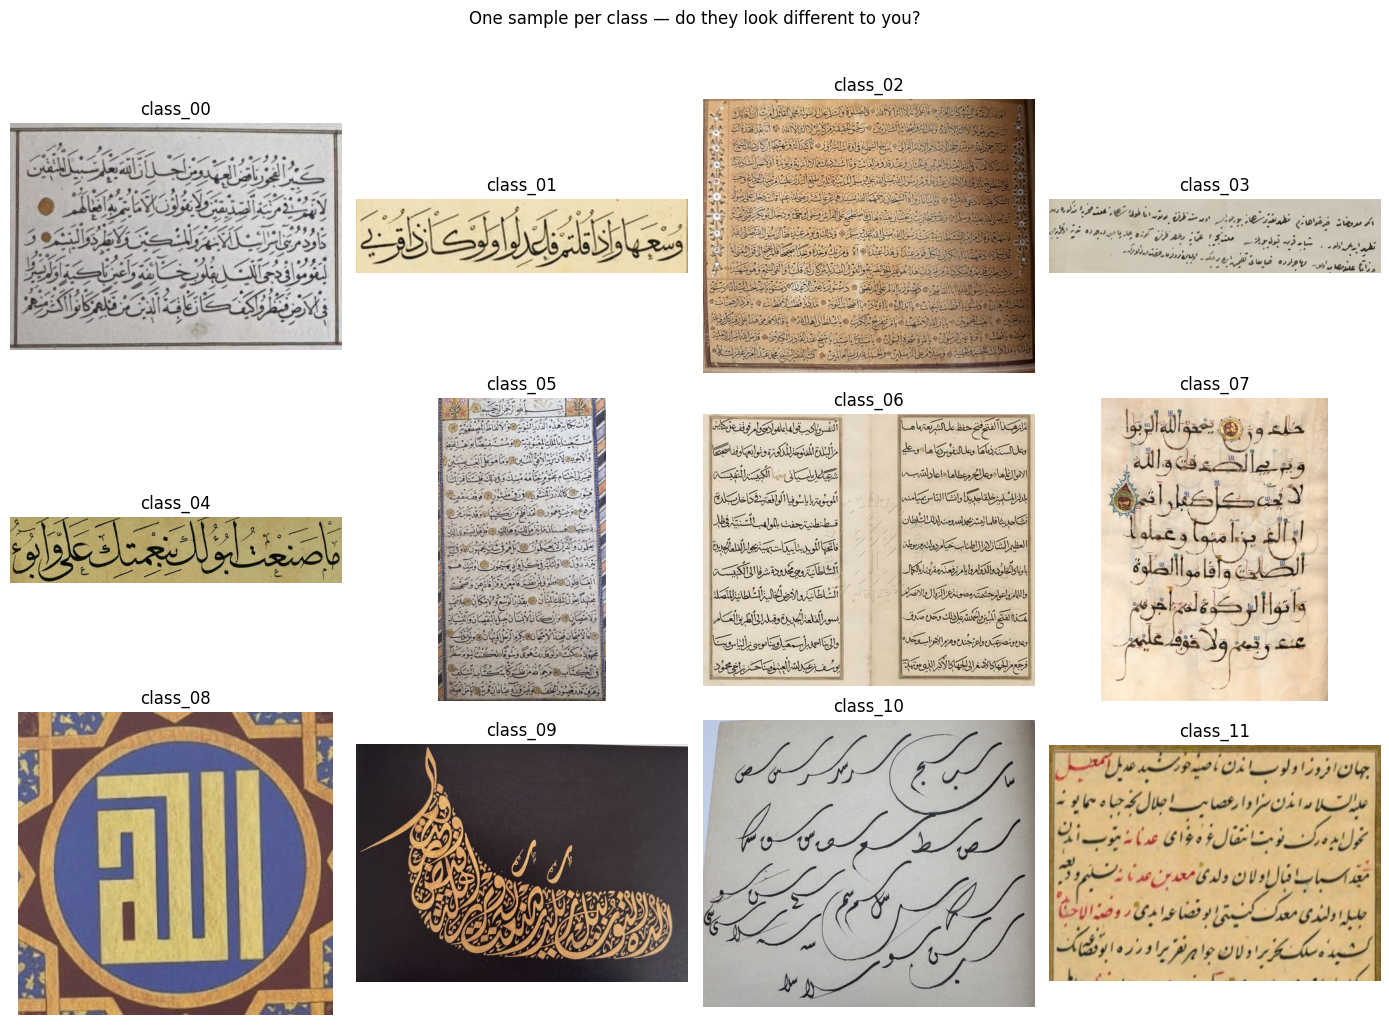

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
# One sample from each of the 12 classes
for cls_idx in range(12):
    row, col = cls_idx // 4, cls_idx % 4
    sample_id = train_df[train_df["label"] == cls_idx].iloc[0]["id"]
    img = Image.open(TRAIN_DIR / f"{sample_id}.jpg").convert("RGB")
    axes[row, col].imshow(img)
    axes[row, col].set_title(f"class_{cls_idx:02d}")
    axes[row, col].axis("off")
plt.suptitle("One sample per class — do they look different to you?", y=1.02)
plt.tight_layout()
plt.show()


## 3. v1: Pretrained EfficientNet-B0
ImageNet-pretrained EfficientNet-B0, augmentation (no horizontal flip, since Arabic script has direction), stratified 80/20 split, AdamW + cosine schedule, label smoothing.

In [12]:
import time, copy
import numpy as np, pandas as pd, torch, torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

torch.manual_seed(42); np.random.seed(42)
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMG = 288
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

# تجهيز الصور: للتدريب نغيّرها شوي عشان النموذج يتعلم أحسن (في البداية بدون قلب، لأن الكتابة العربية لها اتجاه)
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG, scale=(0.6, 1.0), ratio=(0.75, 1.33)),
    transforms.RandomRotation(5),
    transforms.ColorJitter(0.3, 0.3, 0.3, 0.05),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG, IMG)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class CalliDS(Dataset):
    def __init__(self, df, folder, tf, labels=True):
        self.ids = df["id"].tolist()
        self.folder, self.tf = folder, tf
        self.y = df["label"].tolist() if labels else None
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        img = Image.open(self.folder / f"{self.ids[i]}.jpg").convert("RGB")
        x = self.tf(img)
        return (x, self.y[i]) if self.y is not None else (x, self.ids[i])

# تقسيم عادل: كل نوع خط ياخذ نفس النسبة في val ,test
tr2, va2 = train_test_split(train_df, test_size=0.2, stratify=train_df["label"], random_state=42)
train_dl = DataLoader(CalliDS(tr2, TRAIN_DIR, train_tf), batch_size=32, shuffle=True, num_workers=2)
val_dl   = DataLoader(CalliDS(va2, TRAIN_DIR, eval_tf), batch_size=64, num_workers=2)
test_dl  = DataLoader(CalliDS(test_df, TEST_DIR, eval_tf, labels=False), batch_size=64, num_workers=2)

# نموذج جاهز متدرب على ImageNet (مسموح)
net = models.efficientnet_b0(weights="IMAGENET1K_V1")
net.classifier[1] = nn.Linear(net.classifier[1].in_features, 12)
net = net.to(DEV)

EPOCHS = 15
opt = torch.optim.AdamW(net.parameters(), lr=3e-4, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)

best_f1, best_state = -1, None
for ep in range(EPOCHS):
    t0 = time.time()
    net.train()
    for x, y in train_dl:
        x, y = x.to(DEV), y.to(DEV)
        opt.zero_grad()
        loss = loss_fn(net(x), y)
        loss.backward()
        opt.step()
    sched.step()

    net.eval(); P, T = [], []
    with torch.no_grad():
        for x, y in val_dl:
            P += net(x.to(DEV)).argmax(1).cpu().tolist()
            T += y.tolist()
    f1 = f1_score(T, P, average="macro")
    if f1 > best_f1:
        best_f1, best_state = f1, copy.deepcopy(net.state_dict())
    print(f"epoch {ep+1}/{EPOCHS}  val_macro_F1={f1:.3f}  ({time.time()-t0:.0f}s)")

print(f"\n✓ Best validation macro F1: {best_f1:.3f}")

# نستخدم أفضل نسخة ونخمّن صور الاختبار
net.load_state_dict(best_state); net.eval()
ids, preds = [], []
with torch.no_grad():
    for x, i in test_dl:
        preds += net(x.to(DEV)).argmax(1).cpu().tolist()
        ids += list(i)

sub = pd.DataFrame({"id": ids, "label": preds})
sub.to_csv("submission.csv", index=False)
print(f"\nWrote submission.csv with {len(sub)} rows")
print("Prediction distribution:")
print(sub["label"].value_counts().sort_index().to_string())

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 231MB/s]


epoch 1/15  val_macro_F1=0.590  (8s)
epoch 2/15  val_macro_F1=0.653  (7s)
epoch 3/15  val_macro_F1=0.683  (7s)
epoch 4/15  val_macro_F1=0.731  (8s)
epoch 5/15  val_macro_F1=0.756  (7s)
epoch 6/15  val_macro_F1=0.738  (8s)
epoch 7/15  val_macro_F1=0.728  (7s)
epoch 8/15  val_macro_F1=0.721  (7s)
epoch 9/15  val_macro_F1=0.757  (8s)
epoch 10/15  val_macro_F1=0.713  (7s)
epoch 11/15  val_macro_F1=0.737  (8s)
epoch 12/15  val_macro_F1=0.720  (7s)
epoch 13/15  val_macro_F1=0.726  (7s)
epoch 14/15  val_macro_F1=0.734  (8s)
epoch 15/15  val_macro_F1=0.748  (7s)

✓ Best validation macro F1: 0.757

Wrote submission.csv with 260 rows
Prediction distribution:
label
0     16
1     16
2     20
3     23
4     12
5     21
6     14
7     22
8     22
9     30
10    22
11    42


## 4. v2: 5-fold ensemble
Stratified 5-fold CV, EfficientNet-B0 and ConvNeXt-Tiny (10 models), mixed precision, test-time augmentation, and a class-balancing step on predictions to suit macro F1.

In [13]:
#v2: The Supercharged Version
import time, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score

DATA = Path("/kaggle/input/competitions/olo-academy-arabic-classification-challenge/mystery_script")
train_df = pd.read_csv(DATA / "train.csv")
test_df  = pd.read_csv(DATA / "test.csv")
DEV = torch.device("cuda")
torch.manual_seed(42); np.random.seed(42)
NC, IMG, FOLDS, EPOCHS = 12, 320, 5, 10
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

# 1) نحمّل كل الصور مرة وحدة في الذاكرة (أسرع)
def load(folder, ids):
    out = {}
    for i in ids:
        im = Image.open(folder / f"{i}.jpg").convert("RGB")
        im.thumbnail((512, 512))
        out[i] = im
    return out
print("Loading images...")
CACHE = {**load(DATA / "train", train_df["id"]), **load(DATA / "test", test_df["id"])}

# 2) تجهيز الصور
norm = [transforms.ToTensor(), transforms.Normalize(MEAN, STD)]
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG, scale=(0.5, 1.0), ratio=(0.7, 1.4)),
    transforms.RandomRotation(5),
    transforms.ColorJitter(0.3, 0.3, 0.3, 0.05),
    transforms.RandomGrayscale(0.1),
    *norm])
tta_tfs = [  # يطالع الصورة من زاويتين: كاملة + مقرّبة
    transforms.Compose([transforms.Resize((IMG, IMG)), *norm]),
    transforms.Compose([transforms.Resize(int(IMG * 1.25)), transforms.CenterCrop(IMG), *norm]),
]

class DS(Dataset):
    def __init__(s, ids, labels, tf):
        s.ids, s.y, s.tf = list(ids), labels, tf
    def __len__(s):
        return len(s.ids)
    def __getitem__(s, i):
        return s.tf(CACHE[s.ids[i]]), (int(s.y[i]) if s.y is not None else -1)

# 3) النماذج
def make(name):
    if name == "effnet_b0":
        m = models.efficientnet_b0(weights="IMAGENET1K_V1")
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, NC); lr = 3e-4
    else:
        m = models.convnext_tiny(weights="IMAGENET1K_V1")
        m.classifier[2] = nn.Linear(m.classifier[2].in_features, NC); lr = 1e-4
    return m.to(DEV), lr

def predict(m, ids):
    m.eval(); total = 0
    for tf in tta_tfs:
        dl = DataLoader(DS(ids, None, tf), batch_size=64, num_workers=4)
        out = []
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
            for x, _ in dl:
                out.append(F.softmax(m(x.to(DEV)).float(), 1).cpu().numpy())
        total = total + np.concatenate(out)
    return total / len(tta_tfs)

# 4) التدريب: نموذجين × 5 أقسام = 10 نماذج
ids_all, y_all = train_df["id"].values, train_df["label"].values
test_ids = test_df["id"].values
NAMES = ["effnet_b0", "convnext_tiny"]
oof = {k: np.zeros((len(train_df), NC)) for k in NAMES}
tst = {k: np.zeros((len(test_df), NC)) for k in NAMES}
loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)
skf = StratifiedKFold(FOLDS, shuffle=True, random_state=42)
t0 = time.time()

for name in NAMES:
    for fold, (tr, va) in enumerate(skf.split(ids_all, y_all)):
        m, lr = make(name)
        dl = DataLoader(DS(ids_all[tr], y_all[tr], train_tf), batch_size=32,
                        shuffle=True, num_workers=4, drop_last=True)
        opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=0.05)
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr,
                    total_steps=EPOCHS * len(dl), pct_start=0.15)
        scaler = torch.amp.GradScaler("cuda")
        for ep in range(EPOCHS):
            m.train()
            for x, y in dl:
                x, y = x.to(DEV), y.to(DEV)
                opt.zero_grad()
                with torch.autocast("cuda", dtype=torch.float16):
                    loss = loss_fn(m(x), y)
                scaler.scale(loss).backward()
                scaler.step(opt); scaler.update(); sched.step()
        oof[name][va] = predict(m, ids_all[va])
        tst[name] += predict(m, test_ids) / FOLDS
        f1 = f1_score(y_all[va], oof[name][va].argmax(1), average="macro")
        print(f"{name:14s} fold {fold+1}/{FOLDS}  F1={f1:.3f}   ({(time.time()-t0)/60:.1f} min)")
        del m; torch.cuda.empty_cache()
    print(f"==> {name} overall F1 = {f1_score(y_all, oof[name].argmax(1), average='macro'):.3f}\n")

# 5) موازنة التخمينات (عشان Macro F1)
def balance(P, target, iters=300):
    w = np.ones(P.shape[1])
    for _ in range(iters):
        cnt = np.bincount((P * w).argmax(1), minlength=P.shape[1]) + 1e-6
        w *= (target / cnt) ** 0.05
    return (P * w).argmax(1)

train_target = np.bincount(y_all, minlength=NC).astype(float)
test_target = train_target / train_target.sum() * len(test_df)

oof_ens = (oof["effnet_b0"] + oof["convnext_tiny"]) / 2
tst_ens = (tst["effnet_b0"] + tst["convnext_tiny"]) / 2

# 6) نقارن كل الخيارات على الـ800 صورة ونختار الأفضل
options = {
    "effnet only":        (oof["effnet_b0"].argmax(1),     lambda: tst["effnet_b0"].argmax(1)),
    "convnext only":      (oof["convnext_tiny"].argmax(1), lambda: tst["convnext_tiny"].argmax(1)),
    "ensemble":           (oof_ens.argmax(1),              lambda: tst_ens.argmax(1)),
    "ensemble + balance": (balance(oof_ens, train_target), lambda: balance(tst_ens, test_target)),
}
print("===== Comparison (macro F1 on all 800 images) =====")
scores = {}
for k, (p, _) in options.items():
    scores[k] = f1_score(y_all, p, average="macro")
    print(f"{k:20s} {scores[k]:.3f}")
best = max(scores, key=scores.get)
print(f"\n🏆 Best: {best}  ({scores[best]:.3f})")

final = options[best][1]()
sub = pd.DataFrame({"id": test_ids, "label": final})
sub.to_csv("submission_v2.csv", index=False)
print(f"\nWrote submission_v2.csv with {len(sub)} rows")
print("Prediction distribution:")
print(sub["label"].value_counts().sort_index().to_string())
print(f"\nTotal time: {(time.time()-t0)/60:.1f} min")

Loading images...
effnet_b0      fold 1/5  F1=0.901   (1.2 min)
effnet_b0      fold 2/5  F1=0.924   (2.1 min)
effnet_b0      fold 3/5  F1=0.925   (3.0 min)
effnet_b0      fold 4/5  F1=0.848   (4.0 min)
effnet_b0      fold 5/5  F1=0.862   (4.9 min)
==> effnet_b0 overall F1 = 0.891

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 222MB/s] 


convnext_tiny  fold 1/5  F1=0.920   (6.6 min)
convnext_tiny  fold 2/5  F1=0.925   (8.0 min)
convnext_tiny  fold 3/5  F1=0.937   (9.4 min)
convnext_tiny  fold 4/5  F1=0.918   (10.8 min)
convnext_tiny  fold 5/5  F1=0.919   (12.2 min)
==> convnext_tiny overall F1 = 0.924

===== Comparison (macro F1 on all 800 images) =====
effnet only          0.891
convnext only        0.924
ensemble             0.928
ensemble + balance   0.932

🏆 Best: ensemble + balance  (0.932)

Wrote submission_v2.csv with 260 rows
Prediction distribution:
label
0     22
1     21
2     21
3     22
4     22
5     22
6     22
7     22
8     22
9     21
10    21
11    22

Total time: 12.2 min


Version,Model,Validation F1,Public Score
v1,EfficientNet (1 model),0.757,0.770
v2 Supercharged,EfficientNet + ConvNeXt (10 models),0.932,?


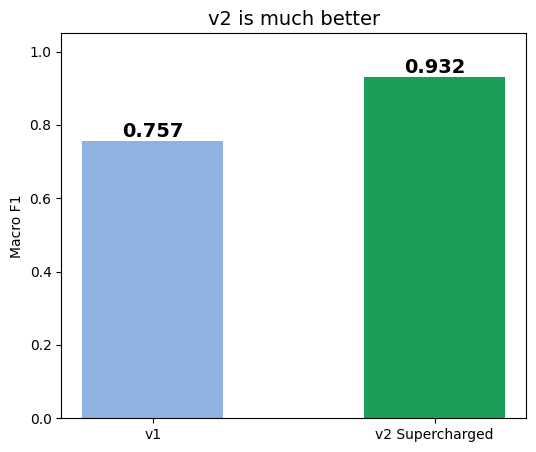

In [17]:
# ===================== v1 vs v2 (simple) =====================
import pandas as pd, matplotlib.pyplot as plt
from IPython.display import display

# جدول مرتب
table = pd.DataFrame({
    "Version":       ["v1", "v2 Supercharged"],
    "Model":         ["EfficientNet (1 model)", "EfficientNet + ConvNeXt (10 models)"],
    "Validation F1": [0.757, 0.932],
    "Public Score":  [0.77, "?"],
})
display(table.style.hide(axis="index").format(precision=3))

# رسم بسيط: عمودين
plt.figure(figsize=(6, 5))
bars = plt.bar(["v1", "v2 Supercharged"], [0.757, 0.932], color=["#8fb3e0", "#1b9e5a"], width=0.5)
plt.bar_label(bars, fmt="%.3f", fontsize=14, fontweight="bold")
plt.ylim(0, 1.05)
plt.ylabel("Macro F1")
plt.title("v2 is much better", fontsize=14)
plt.show()

## 5. v3: Higher-resolution ensemble
ConvNeXt-Tiny and EfficientNetV2-S at 384 px, 15 epochs per fold; all model combinations compared on out-of-fold predictions.

In [18]:
# ===================== v3: The Ultimate Version =====================
import itertools
IMG2, EPOCHS2 = 384, 15
norm2 = [transforms.ToTensor(), transforms.Normalize(MEAN, STD)]
train_tf2 = transforms.Compose([
    transforms.RandomResizedCrop(IMG2, scale=(0.5, 1.0), ratio=(0.7, 1.4)),
    transforms.RandomRotation(5),
    transforms.ColorJitter(0.3, 0.3, 0.3, 0.05),
    transforms.RandomGrayscale(0.1), *norm2])
tta2 = [transforms.Compose([transforms.Resize((IMG2, IMG2)), *norm2]),
        transforms.Compose([transforms.Resize(int(IMG2 * 1.25)), transforms.CenterCrop(IMG2), *norm2])]

def make2(name):
    if name == "convnext_tiny_384":
        m = models.convnext_tiny(weights="IMAGENET1K_V1")
        m.classifier[2] = nn.Linear(m.classifier[2].in_features, NC); lr = 1e-4
    else:
        m = models.efficientnet_v2_s(weights="IMAGENET1K_V1")
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, NC); lr = 3e-4
    return m.to(DEV), lr

def predict2(m, ids):
    m.eval(); total = 0
    for tf in tta2:
        dl = DataLoader(DS(ids, None, tf), batch_size=32, num_workers=4)
        out = []
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
            for x, _ in dl:
                out.append(F.softmax(m(x.to(DEV)).float(), 1).cpu().numpy())
        total = total + np.concatenate(out)
    return total / len(tta2)

t0 = time.time()
for name in ["convnext_tiny_384", "effnetv2_s_384"]:
    oof[name] = np.zeros((len(train_df), NC))
    tst[name] = np.zeros((len(test_df), NC))
    for fold, (tr, va) in enumerate(skf.split(ids_all, y_all)):
        torch.manual_seed(fold)
        m, lr = make2(name)
        dl = DataLoader(DS(ids_all[tr], y_all[tr], train_tf2), batch_size=24,
                        shuffle=True, num_workers=4, drop_last=True)
        opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=0.05)
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr,
                    total_steps=EPOCHS2 * len(dl), pct_start=0.15)
        scaler = torch.amp.GradScaler("cuda")
        for ep in range(EPOCHS2):
            m.train()
            for x, y in dl:
                x, y = x.to(DEV), y.to(DEV)
                opt.zero_grad()
                with torch.autocast("cuda", dtype=torch.float16):
                    loss = loss_fn(m(x), y)
                scaler.scale(loss).backward()
                scaler.step(opt); scaler.update(); sched.step()
        oof[name][va] = predict2(m, ids_all[va])
        tst[name] += predict2(m, test_ids) / FOLDS
        f1 = f1_score(y_all[va], oof[name][va].argmax(1), average="macro")
        print(f"{name:18s} fold {fold+1}/{FOLDS}  F1={f1:.3f}   ({(time.time()-t0)/60:.1f} min)")
        del m; torch.cuda.empty_cache()
    print(f"==> {name} overall F1 = {f1_score(y_all, oof[name].argmax(1), average='macro'):.3f}\n")

# نجرب كل التركيبات بين النماذج الأربعة ونختار الأفضل
results = []
names = list(oof.keys())
for r in range(1, len(names) + 1):
    for combo in itertools.combinations(names, r):
        P = sum(oof[n] for n in combo) / len(combo)
        results.append((f1_score(y_all, balance(P, train_target), average="macro"), "balance", combo))
        results.append((f1_score(y_all, P.argmax(1), average="macro"), "plain", combo))
results.sort(key=lambda t: t[0], reverse=True)
print("===== Top combinations (macro F1 on 800 images) =====")
for s, mode, combo in results[:6]:
    print(f"{s:.3f}  {mode:8s} {' + '.join(combo)}")

best_s, best_mode, best_combo = results[0]
PT = sum(tst[n] for n in best_combo) / len(best_combo)
final = balance(PT, test_target) if best_mode == "balance" else PT.argmax(1)
pd.DataFrame({"id": test_ids, "label": final}).to_csv("submission_v3.csv", index=False)
print(f"\nBEST v3: {best_s:.3f}   |   v2 was: {scores['ensemble + balance']:.3f}")
print(f"Wrote submission_v3.csv   (total {(time.time()-t0)/60:.1f} min)")

convnext_tiny_384  fold 1/5  F1=0.932   (3.1 min)
convnext_tiny_384  fold 2/5  F1=0.949   (5.8 min)
convnext_tiny_384  fold 3/5  F1=0.929   (8.6 min)
convnext_tiny_384  fold 4/5  F1=0.943   (11.4 min)
convnext_tiny_384  fold 5/5  F1=0.888   (14.1 min)
==> convnext_tiny_384 overall F1 = 0.928

Downloading: "https://download.pytorch.org/models/efficientnet_v2_s-dd5fe13b.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_v2_s-dd5fe13b.pth


100%|██████████| 82.7M/82.7M [00:00<00:00, 185MB/s] 


effnetv2_s_384     fold 1/5  F1=0.951   (17.2 min)
effnetv2_s_384     fold 2/5  F1=0.948   (20.1 min)
effnetv2_s_384     fold 3/5  F1=0.922   (22.9 min)
effnetv2_s_384     fold 4/5  F1=0.927   (25.8 min)
effnetv2_s_384     fold 5/5  F1=0.900   (28.7 min)
==> effnetv2_s_384 overall F1 = 0.929

===== Top combinations (macro F1 on 800 images) =====
0.956  balance  convnext_tiny_384 + effnetv2_s_384
0.953  balance  convnext_tiny + convnext_tiny_384 + effnetv2_s_384
0.951  balance  effnet_b0 + convnext_tiny + convnext_tiny_384 + effnetv2_s_384
0.950  balance  convnext_tiny + effnetv2_s_384
0.949  balance  effnet_b0 + convnext_tiny_384 + effnetv2_s_384
0.947  balance  effnet_b0 + convnext_tiny + convnext_tiny_384

BEST v3: 0.956   |   v2 was: 0.932
Wrote submission_v3.csv   (total 28.7 min)
